# Vision — OCR Tabel: gambar tabel → DataFrame
**Kapan dipakai:** soal berisi foto/scan tabel dan isinya harus dijadikan data.

**Langkah:** EasyOCR `detail=1` (teks + kotak) → kelompokkan kotak per baris (posisi y) →
tentukan kolom dari posisi x kiri judul kolom. Tidak butuh garis tabel, jadi juga jalan untuk
tabel tanpa garis.

**Data demo:** 40 gambar tabel harga SINTETIS (4 kolom). Kunci = `tabel.csv`
(path, baris, kolom, teks), satu baris per sel.

In [1]:
import cv2
import easyocr
import jiwer
import matplotlib.pyplot as plt
import pandas as pd
import torch

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/ocr"   # GANTI saat lomba
KEY_CSV = f"{DATA_FOLDER}/tabel.csv"     # hanya ada di data latihan
EASYOCR_FOLDER = "Z:/GEMASTIK-DATABASE/pretrained/easyocr"

LANGUAGES = ["en", "id"]
ROW_TOLERANCE = 15   # piksel, kotak dengan selisih tengah-y lebih kecil = satu baris
MARGIN_X = 15        # piksel, teks boleh mulai sedikit di kiri judul kolomnya

## Baca data

tabel: 40 | sel: 892


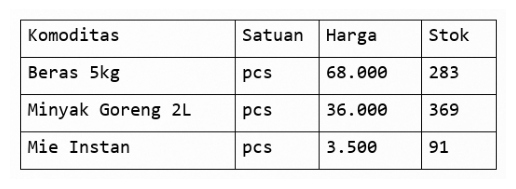

In [3]:
key = pd.read_csv(KEY_CSV)
image_paths = list(key["path"].unique())
print("tabel:", len(image_paths), "| sel:", len(key))

first_image = cv2.imread(f"{DATA_FOLDER}/{image_paths[0]}")
plt.imshow(first_image)
plt.axis("off")
plt.show()

## Kelompokkan kotak OCR per baris
Hasil EasyOCR per kotak: `(4 titik sudut, teks, keyakinan)`. Kotak diurutkan dari atas ke
bawah, baris baru dimulai bila tengah-y melompat lebih dari `ROW_TOLERANCE`.

In [4]:
reader = easyocr.Reader(LANGUAGES, gpu=torch.cuda.is_available(),
                        model_storage_directory=EASYOCR_FOLDER,
                        user_network_directory=EASYOCR_FOLDER,
                        download_enabled=False, verbose=False)


def center_y(item):
    box = item[0]
    return (box[0][1] + box[2][1]) / 2      # rata-rata y sudut kiri atas dan kanan bawah


def group_rows(ocr_result):
    rows = []
    previous_y = -1000
    for item in sorted(ocr_result, key=center_y):
        box, text, confidence = item
        if center_y(item) - previous_y > ROW_TOLERANCE:
            rows.append([])
        rows[-1].append((box[0][0], text))   # (x kiri, teks)
        previous_y = center_y(item)
    for row in rows:
        row.sort()                            # kiri ke kanan
    return rows


first_rows = group_rows(reader.readtext(f"{DATA_FOLDER}/{image_paths[0]}", width_ths=0.3))
print(first_rows[:3])

[[(np.int32(16), 'Komoditas'), (np.int32(247), 'Satuan'), (np.int32(335), 'Harga'), (np.int32(447), 'Stok')], [(np.int32(17), 'Beras'), (np.int32(82), '5kg'), (np.int32(246), 'pcs'), (np.int32(337), '68'), (np.int32(369), '000'), (np.int32(447), '283')], [(np.int32(16), 'Minyak'), (np.int32(91), 'Goreng'), (np.int32(171), '2L'), (np.int32(246), 'pcs'), (np.int32(337), '36'), (np.int32(369), '000'), (np.int32(447), '369')]]


## Ubah satu gambar jadi tabel sel (path, baris, kolom, teks)
Kolom = judul kolom paling kanan yang posisi x kirinya masih di kiri teks.

In [5]:
def to_cells(path):
    rows = group_rows(reader.readtext(f"{DATA_FOLDER}/{path}", width_ths=0.3))
    header_lefts = []
    for left, text in rows[0]:
        header_lefts.append(left)
    cells = []
    for row_number in range(len(rows)):
        for left, text in rows[row_number]:
            column = 0
            for column_number in range(len(header_lefts)):
                if header_lefts[column_number] <= left + MARGIN_X:
                    column = column_number
            cells.append([path, row_number, column, text])
    table = pd.DataFrame(cells, columns=["path", "baris", "kolom", "teks"])
    table = table.groupby(["path", "baris", "kolom"], as_index=False)["teks"].agg(" ".join)
    return table


tables = []
for path in image_paths:
    tables.append(to_cells(path))
guess = pd.concat(tables)
guess.head(8)

,path,baris,kolom,teks
0,tabel/tabel000.png,0,0,Komoditas
1,tabel/tabel000.png,0,1,Satuan
2,tabel/tabel000.png,0,2,Harga
3,tabel/tabel000.png,0,3,Stok
4,tabel/tabel000.png,1,0,Beras 5kg
5,tabel/tabel000.png,1,1,pcs
6,tabel/tabel000.png,1,2,68 000
7,tabel/tabel000.png,1,3,283


## Evaluasi: sel tepat dan CER (memakai kunci, hanya untuk latihan)
Tiap sel kunci dicari pasangannya di tebakan lewat (path, baris, kolom).

In [6]:
guess_lookup = {}
for path, row, column, text in zip(guess["path"], guess["baris"], guess["kolom"], guess["teks"]):
    guess_lookup[(path, row, column)] = text

evaluation = key.copy()
guessed_texts = []
for path, row, column in zip(key["path"], key["baris"], key["kolom"]):
    guessed_texts.append(guess_lookup.get((path, row, column), ""))   # "" = sel tidak terbaca
evaluation["teks_tebak"] = guessed_texts
evaluation["tepat"] = evaluation["teks"].str.lower() == evaluation["teks_tebak"].str.lower()
print("sel tepat:", round(evaluation["tepat"].mean(), 4))
print("CER:", round(jiwer.cer(list(evaluation["teks"]), list(evaluation["teks_tebak"])), 4))
print("akurasi per kolom:")
print(evaluation.groupby("kolom")["tepat"].mean())

sel tepat: 0.9249
CER: 0.0165
akurasi per kolom:
kolom
0    0.892377
1    0.982063
2    0.838565
3    0.986547
Name: tepat, dtype: float64


## Hasil: satu tabel jadi DataFrame lebar (baris x kolom)
Baris pertama hasil OCR dipakai sebagai nama kolom.

In [7]:
one_table = guess[guess["path"] == image_paths[0]]
wide = one_table.pivot(index="baris", columns="kolom", values="teks")
wide.columns = wide.iloc[0]
wide = wide.iloc[1:]
wide.to_csv("tabel_contoh.csv", index=False)
guess.to_csv("semua_sel.csv", index=False)
wide

,Komoditas,Satuan,Harga,Stok
baris,,,,
1,Beras 5kg,pcs,68 000,283
2,Minyak Goreng 2L,pcs,36 000,369
3,Mie Instan,pcs,500,91
